# OCR Hallucinations — Where Should We Get Synthetic Data From?

**Scope:** OCR hallucination category only (not mischaracterization, invention, miscounting, or other).

**Goal:** decide what OCR synthetic/external data to build, by answering 3 questions:
1. How rare is OCR vs. the other categories?
2. Do clean (non-hallucinated) OCR-context examples exist in `train`?
3. Does `train` differ from `test` in visual domain or prompt theme?

**Data:** `data/train.jsonl`, `data/val.jsonl`, `data/test.jsonl` + images in `shroom-vis-images/`. `test.jsonl` is unlabeled (shared-task submission set) but still has prompts/images to compare.

---
## TL;DR

- OCR is the **rarest** hallucination type — ~1,284 spans vs. 13,600+ for invention/mischaracterization.
- OCR spans are **short** — median 5 characters, not a sentence.
- **~22%** of `train` prompts that sound like OCR are actually clean (no hallucination) — negatives matter.
- **~41%** of real OCR hallucinations happen on prompts that never mention text at all.
- OCR hallucinations occur almost only in **real candid photos** (90%), almost never in stock object photos.
- `train`/`test` share **zero images** and skew toward different text themes: train → dates/vehicles, test → documents/signage.
- **Bottom line:** source new OCR data from real photos with visible text (not object catalogs), prioritize documents/signage, keep spans short, and keep some clean examples.

In [1]:
import json
import re
import collections
import statistics
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.05)
PALETTE = sns.color_palette("Set2", 8)

DATA_DIR = Path("data")
IMAGE_DIR = Path("shroom-vis-images")
if not DATA_DIR.exists():
    DATA_DIR = Path("..") / "data"
    IMAGE_DIR = Path("..") / "shroom-vis-images"

LANGUAGES = ["en", "fr", "it", "zh"]
LANG_NAMES = {"en": "English", "fr": "French", "it": "Italian", "zh": "Chinese"}
LABEL_ORDER = ["invention", "mischaracterization", "miscounting", "OCR", "other"]
LABEL_COLORS = dict(zip(LABEL_ORDER, PALETTE))


def load_jsonl(path: Path) -> list:
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


train = load_jsonl(DATA_DIR / "train.jsonl")
val = load_jsonl(DATA_DIR / "val.jsonl")
test = load_jsonl(DATA_DIR / "test.jsonl")

print(f"train: {len(train):>6,d} samples")
print(f"val:   {len(val):>6,d} samples")
print(f"test:  {len(test):>6,d} samples  (unlabeled)")

train: 12,082 samples
val:    3,020 samples
test:   4,898 samples  (unlabeled)


---
## 1. Dataset overview

Split sizes, plus a key check for later: do `train`/`val` and `test` share any images?

In [2]:
def has_label(d, lab):
    return any(l["label"] == lab for l in d.get("labels", []))


overview_rows = []
for name, data in [("train", train), ("val", val), ("test", test)]:
    langs = collections.Counter(d["language"] for d in data)
    n_hallu = sum(1 for d in data if d.get("labels")) if name != "test" else None
    overview_rows.append({
        "split": name,
        "n_samples": len(data),
        "n_images": len(set(d["image_name"] for d in data)),
        **{f"n_{l}": langs[l] for l in LANGUAGES},
        "n_with_hallucination": n_hallu,
    })

overview_df = pd.DataFrame(overview_rows).set_index("split")
overview_df

,n_samples,n_images,n_en,n_fr,n_it,n_zh,n_with_hallucination
split,,,,,,,
train,12082,2054,3070,3013,2989,3010,8646.0
val,3020,1473,729,754,757,780,2161.0
test,4898,400,1201,1233,1254,1210,NaN


In [3]:
train_val_images = set(d["image_name"] for d in train + val)
test_images = set(d["image_name"] for d in test)
overlap = train_val_images & test_images

print(f"Unique images in train+val: {len(train_val_images):,d}")
print(f"Unique images in test:      {len(test_images):,d}")
print(f"Images shared between them: {len(overlap):,d}")

Unique images in train+val: 2,076
Unique images in test:      400
Images shared between them: 0


**Finding:** Zero shared images. Every test photo is unseen — so any "distribution shift" found below is about *what kind* of photo/prompt appears, not memorized images.

---
## 2. Class balance

How many hallucination spans of each type exist, and how does OCR compare?

In [4]:
def label_counts(data):
    c = collections.Counter()
    for d in data:
        for l in d.get("labels", []):
            c[l["label"]] += 1
    return c

def sample_counts_with_label(data, lab):
    return sum(1 for d in data if has_label(d, lab))

rows = []
for lab in LABEL_ORDER:
    rows.append({
        "category": lab,
        "train_spans": label_counts(train)[lab],
        "val_spans": label_counts(val)[lab],
        "train_samples_with_label": sample_counts_with_label(train, lab),
        "val_samples_with_label": sample_counts_with_label(val, lab),
    })
class_balance_df = pd.DataFrame(rows).set_index("category").sort_values("train_spans", ascending=False)
class_balance_df

,train_spans,val_spans,train_samples_with_label,val_samples_with_label
category,,,,
invention,14473,3673,4989,1225
mischaracterization,13609,3397,5350,1358
miscounting,2747,687,1484,359
other,1480,330,1080,255
OCR,1284,318,730,179


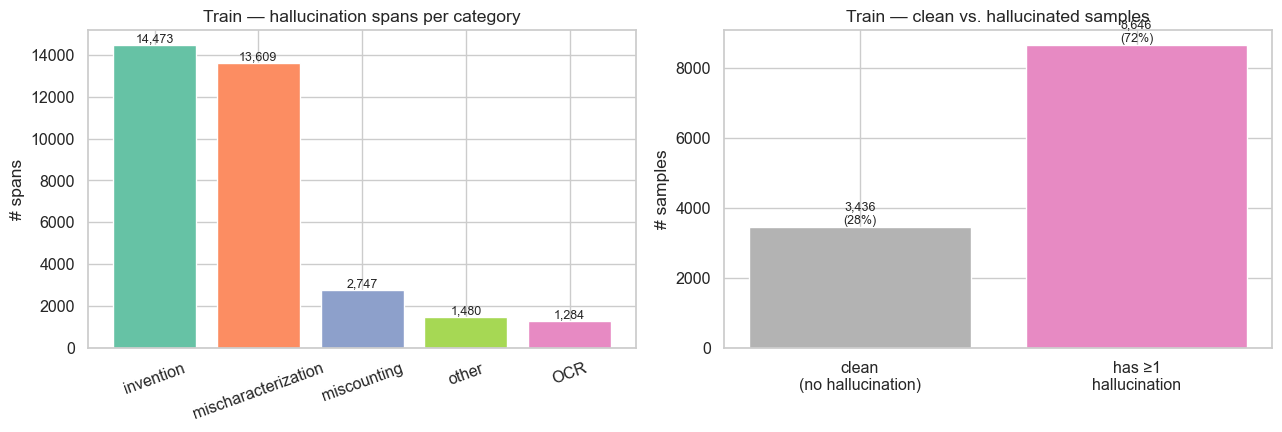

OCR is the RAREST category: 1,284 train spans vs 14,473 for invention (11.3x more).


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

order = class_balance_df.index.tolist()
colors = [LABEL_COLORS[c] for c in order]

axes[0].bar(order, class_balance_df["train_spans"], color=colors)
axes[0].set_title("Train — hallucination spans per category")
axes[0].set_ylabel("# spans")
axes[0].tick_params(axis="x", rotation=20)
for i, v in enumerate(class_balance_df["train_spans"]):
    axes[0].text(i, v + 150, f"{v:,d}", ha="center", fontsize=9)

n_clean_train = sum(1 for d in train if not d.get("labels"))
n_hallu_train = len(train) - n_clean_train
axes[1].bar(["clean\n(no hallucination)", "has \u22651\nhallucination"],
            [n_clean_train, n_hallu_train], color=[PALETTE[7], PALETTE[3]])
axes[1].set_title("Train — clean vs. hallucinated samples")
axes[1].set_ylabel("# samples")
for i, v in enumerate([n_clean_train, n_hallu_train]):
    axes[1].text(i, v + 100, f"{v:,d}\n({100*v/len(train):.0f}%)", ha="center", fontsize=9)

plt.tight_layout()
plt.show()

print(f"OCR is the RAREST category: {class_balance_df.loc['OCR','train_spans']:,d} train spans "
      f"vs {class_balance_df.loc['invention','train_spans']:,d} for invention "
      f"({class_balance_df.loc['invention','train_spans']/class_balance_df.loc['OCR','train_spans']:.1f}x more).")

**Finding:** OCR is the rarest category — **~11x fewer spans** than invention/mischaracterization. That's the core motivation for augmenting it.

In [6]:
span_len_rows = []
for lab in LABEL_ORDER:
    lens = [l["end"] - l["start"] for d in train + val for l in d.get("labels", []) if l["label"] == lab]
    span_len_rows.append({
        "category": lab,
        "n_spans": len(lens),
        "median_len": statistics.median(lens),
        "mean_len": round(statistics.mean(lens), 1),
        "p90_len": int(pd.Series(lens).quantile(0.9)),
    })
span_len_df = pd.DataFrame(span_len_rows).set_index("category").sort_values("median_len")
span_len_df

,n_spans,median_len,mean_len,p90_len
category,,,,
miscounting,3434,3.0,6.2,9
OCR,1602,5.0,8.6,15
mischaracterization,17006,7.0,14.1,31
other,1810,9.0,66.9,130
invention,18146,14.0,27.4,57


**Finding:** OCR spans are also the **shortest** (median 5 characters — a word, code, or a few digits). Synthetic data with long or sentence-level spans won't match this shape.

---
## 3. Clean OCR-context samples in `train`, and how much OCR matters in `test`

There's no "topic" field, so we approximate **"OCR-context"** with a keyword heuristic on the prompt (mentions signs, brands, dates, prices, written text, etc.), validated against real labels before trusting it — then applied to unlabeled `test` too, to gauge how much OCR matters there.

In [7]:
OCR_CONTEXT_KEYWORDS = {
    "en": r"written|writing|says|say\b|reads?\b|sign\b|signage|banner|poster|label|brand|logo|"
          r"letters?\b|word\b|text\b|number\b|digits?\b|year\b|date\b|price\b|name of|title\b|"
          r"caption|menu\b|receipt|ticket|plate\b|store name|event name|concert|clicked|marked|"
          r"engraved|printed|inscription",
    "fr": r"écrit|écrite|inscri|panneau|affiche|marque|logo|lettres?|mot\b|texte|numéro|chiffre|"
          r"année|date\b|prix\b|nom du|titre|menu\b|reçu|ticket|plaque|enseigne|gravé|imprimé",
    "it": r"scritt|cartell|insegna|marca|logo|lettera|parola|testo|numero|cifra|anno\b|data\b|"
          r"prezzo|nome del|titolo|menu\b|ricevuta|biglietto|targa|inciso|stampat",
    "zh": r"写|字|标志|标牌|品牌|标签|文字|数字|年份|日期|价格|名字|名称|标题|菜单|收据|门票|车牌|刻|印|招牌",
}

def is_ocr_context(d):
    return re.search(OCR_CONTEXT_KEYWORDS[d["language"]], d["prompt"].lower(), re.IGNORECASE) is not None

ocr_samples_train = [d for d in train if has_label(d, "OCR")]
flagged_train = [d for d in train if is_ocr_context(d)]

recall = sum(1 for d in ocr_samples_train if is_ocr_context(d)) / len(ocr_samples_train)
precision = sum(1 for d in flagged_train if has_label(d, "OCR")) / len(flagged_train)
print(f"Heuristic recall:    {recall*100:.1f}% of real OCR samples caught by keyword match")
print(f"Heuristic precision: {precision*100:.1f}% of keyword-flagged samples are real OCR")
print("(Coarse heuristic -- numbers below are directional, not exact.)")

Heuristic recall:    58.2% of real OCR samples caught by keyword match
Heuristic precision: 28.6% of keyword-flagged samples are real OCR
(Coarse heuristic -- numbers below are directional, not exact.)


In [8]:
def ocr_context_breakdown(data, name):
    flagged = [d for d in data if is_ocr_context(d)]
    n = len(flagged)
    has_labels_field = any("labels" in d for d in data)   # False for test (unlabeled shared-task split)
    if has_labels_field:
        n_ocr = sum(1 for d in flagged if has_label(d, "OCR"))
        n_other = sum(1 for d in flagged if d.get("labels") and not has_label(d, "OCR"))
        n_clean = sum(1 for d in flagged if not d.get("labels"))
        pct_clean = round(100 * n_clean / n, 1)
    else:
        n_ocr = n_other = n_clean = pct_clean = None   # unknown -- no ground truth to check against
    return {
        "split": name,
        "n_ocr_context_prompts": n,
        "pct_of_split": round(100 * n / len(data), 1),
        "has_OCR_label": n_ocr,
        "has_other_label_only": n_other,
        "CLEAN_no_hallucination": n_clean,
        "pct_clean_of_flagged": pct_clean,
    }

breakdown_df = pd.DataFrame([
    ocr_context_breakdown(train, "train"),
    ocr_context_breakdown(val, "val"),
    ocr_context_breakdown(test, "test"),
]).set_index("split")
breakdown_df

,n_ocr_context_prompts,pct_of_split,has_OCR_label,has_other_label_only,CLEAN_no_hallucination,pct_clean_of_flagged
split,,,,,,
train,1487,12.3,425.0,729.0,333.0,22.4
val,390,12.9,113.0,190.0,87.0,22.3
test,591,12.1,NaN,NaN,NaN,NaN


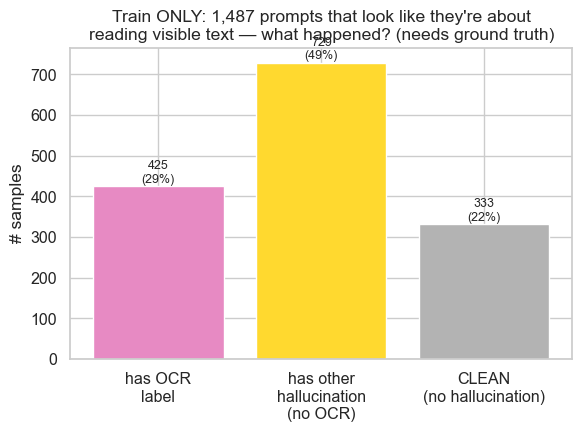

In [9]:
row = breakdown_df.loc["train"]
n_flagged = int(row["n_ocr_context_prompts"])
fig, ax = plt.subplots(figsize=(6, 4.5))
labels = ["has OCR\nlabel", "has other\nhallucination\n(no OCR)", "CLEAN\n(no hallucination)"]
values = [int(row["has_OCR_label"]), int(row["has_other_label_only"]), int(row["CLEAN_no_hallucination"])]
colors = [LABEL_COLORS["OCR"], PALETTE[5], PALETTE[7]]
bars = ax.bar(labels, values, color=colors)
ax.set_title(f"Train ONLY: {n_flagged:,d} prompts that look like they're about\nreading visible text — what happened? (needs ground truth)")
ax.set_ylabel("# samples")
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width()/2, v + 8, f"{v:,d}\n({100*v/n_flagged:.0f}%)", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

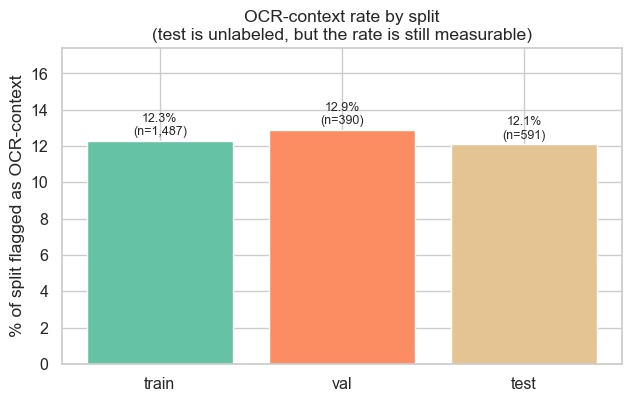

test: 12.1% OCR-context (unlabeled) vs. train: 12.3% -- nearly identical rate.
OCR is not a rare edge case in the scored data.


In [10]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
order = ["train", "val", "test"]
pct_values = [breakdown_df.loc[s, "pct_of_split"] for s in order]
n_values = [int(breakdown_df.loc[s, "n_ocr_context_prompts"]) for s in order]
bar_colors = [PALETTE[0], PALETTE[1], PALETTE[6]]
bars = ax.bar(order, pct_values, color=bar_colors)
ax.set_ylabel("% of split flagged as OCR-context")
ax.set_ylim(0, max(pct_values) * 1.35)
ax.set_title("OCR-context rate by split\n(test is unlabeled, but the rate is still measurable)")
for b, pct, n in zip(bars, pct_values, n_values):
    ax.text(b.get_x() + b.get_width() / 2, pct + 0.3, f"{pct:.1f}%\n(n={n:,d})", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

print(f"test: {pct_values[2]:.1f}% OCR-context (unlabeled) vs. train: {pct_values[0]:.1f}% -- nearly identical rate.")
print("OCR is not a rare edge case in the scored data.")

**Finding:**

- Of ~1,487 `train` prompts that sound like OCR-context, only **~29%** actually carry an OCR label.
- **~22% (333 samples) are fully clean** — the model read it correctly, no hallucination at all.
- The rest (~49%) have a *different* hallucination type (usually mischaracterization or invention).
- `test` shows a near-identical OCR-context rate (**12.1%** vs. train's 12.3%) — OCR isn't a rare edge case in the scored data either.

**Why it matters:** augmentation needs both new hallucinated examples *and* clean negatives — otherwise the detector learns "text-reading prompt ⇒ hallucination" as a shortcut instead of actually judging correctness.

### 3.1 Do OCR hallucinations need a text-reading prompt?

Recall above was only 58% — a lot of real OCR hallucinations slip past the keyword filter. Let's look at that missed set directly.

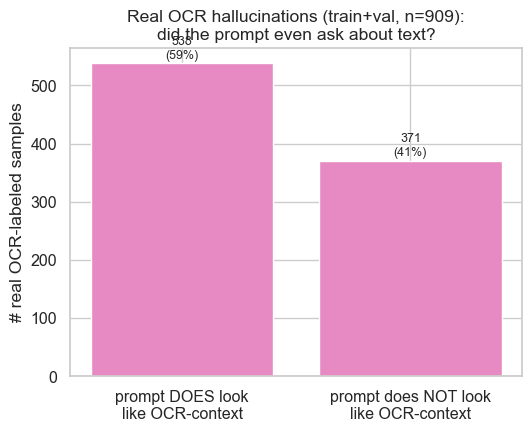

371/909 = 40.8% of real OCR hallucinations have no text-reading cue in the prompt at all.


In [11]:
ocr_samples_all = [d for d in train + val if has_label(d, "OCR")]
ocr_with_context = [d for d in ocr_samples_all if is_ocr_context(d)]
ocr_no_context = [d for d in ocr_samples_all if not is_ocr_context(d)]

n_total = len(ocr_samples_all)
n_no_context = len(ocr_no_context)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
bars = ax.bar(
    ["prompt DOES look\nlike OCR-context", "prompt does NOT look\nlike OCR-context"],
    [len(ocr_with_context), n_no_context],
    color=[LABEL_COLORS["OCR"], PALETTE[3]],
)
ax.set_ylabel("# real OCR-labeled samples")
ax.set_title(f"Real OCR hallucinations (train+val, n={n_total}):\ndid the prompt even ask about text?")
for b, v in zip(bars, [len(ocr_with_context), n_no_context]):
    ax.text(b.get_x() + b.get_width() / 2, v + 8, f"{v:,d}\n({100*v/n_total:.0f}%)", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

print(f"{n_no_context}/{n_total} = {100*n_no_context/n_total:.1f}% of real OCR hallucinations have no text-reading cue in the prompt at all.")

In [12]:
def first_ocr_span(d):
    for l in d.get("labels", []):
        if l["label"] == "OCR":
            return l
    return None

example_rows = []
for d in [x for x in ocr_no_context if x["language"] == "en"][:8]:
    span = first_ocr_span(d)
    example_rows.append({
        "id": d["id"],
        "prompt (nothing about text)": d["prompt"],
        "hallucinated OCR span": d["response"][span["start"]:span["end"]],
        "image_name": d["image_name"],
    })
examples_df = pd.DataFrame(example_rows)
examples_df

,id,prompt (nothing about text),hallucinated OCR span,image_name
0,train-en-803,What is the airport name?,N,14323438711_c9c3d3d270_o.jpg
1,train-en-2396,Is he the boss?,odo,6333959669_db2dea133e_o.jpg
2,train-en-11908,Does this crab have ten legs? Please elaborate.,ten,crab_Porcelain_crab_long-clawed-porcelain-crab...
3,train-en-1855,Is this bathtub white in color? Please elaborate.,LUXWE,bathtub_Wooden_tub_7x4ft-hot-tub-1_1.jpg
4,train-en-10200,Where is the playground located?,USC,2334538958_7bde8f845e_o.jpg
5,train-en-9784,what is the subject of the meeting?,Edan,15443204176_a09a044760_o.jpg
6,train-en-1878,At what time does the bar grill open?,VACHTY,8098_8391482343_5380dfa6bc_o.jpg
7,train-en-9630,what is the subject of the meeting?,ethernet,15443204176_a09a044760_o.jpg


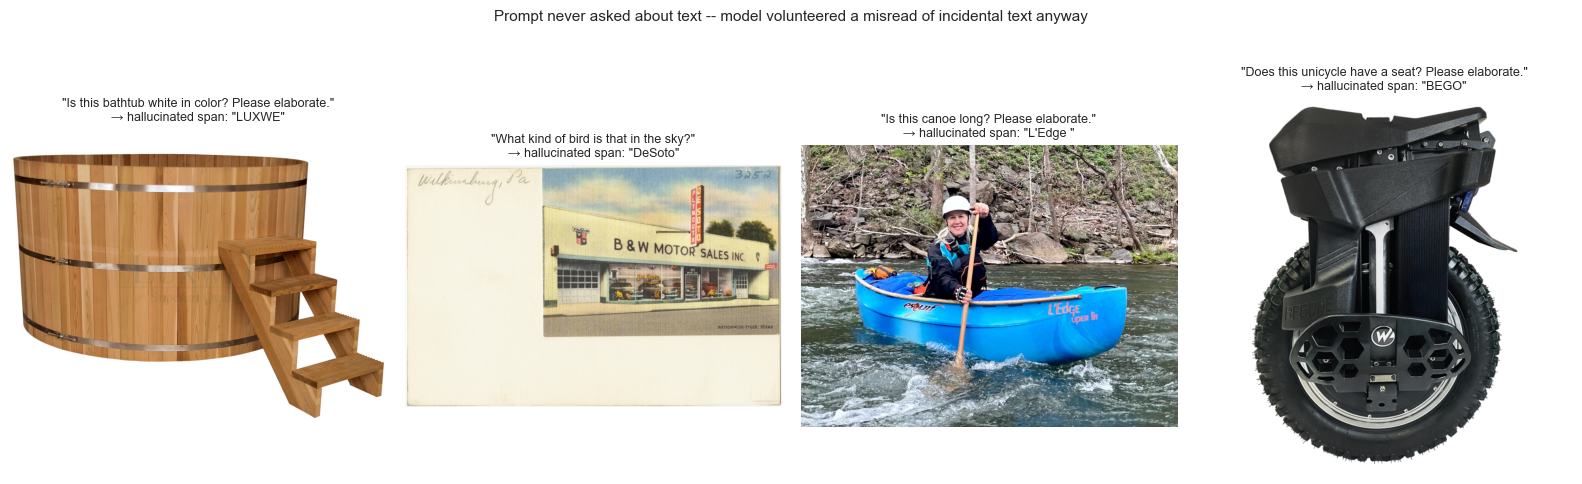

In [13]:
spontaneous_examples = [
    "train-en-1855",   # "Is this bathtub white in color?" -> volunteers a misread of text on a metal band
    "train-en-10802",  # "What kind of bird is that in the sky?" -> ignores the bird, misreads storefront signage
    "train-en-1231",   # "Is this canoe long?" -> volunteers a misread of text printed on the hull
    "train-en-11803",  # "Does this unicycle have a seat?" -> volunteers a misread brand fragment
]
by_id = {d["id"]: d for d in train + val + test}

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for col, sid in enumerate(spontaneous_examples):
    d = by_id[sid]
    span = first_ocr_span(d)
    span_text = d["response"][span["start"]:span["end"]]
    img = mpimg.imread(IMAGE_DIR / d["image_name"])
    axes[col].imshow(img)
    axes[col].axis("off")
    axes[col].set_title(f"\"{d['prompt']}\"\n→ hallucinated span: \"{span_text}\"", fontsize=9)
plt.suptitle("Prompt never asked about text -- model volunteered a misread of incidental text anyway", fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

**Finding: ~41% of OCR hallucinations happen with no text-reading prompt at all.**

371 of 909 real OCR samples have prompts like "Is this bathtub white?" or "Does this unicycle have a seat?" — nothing about text. The model volunteers (and misreads) incidental visible text anyway while elaborating on the actual question.

**Why it matters:** seed selection can't rely on prompt keywords alone. The real requirement is *the image has legible text*, regardless of what the question asks — especially for open-ended "please elaborate" prompts.

---
## 4. Where do OCR hallucinations actually occur?

Images come in two flavors:
- **Object-query** photos (e.g. `cauliflower_...jpg`) — curated single-object stock photos.
- **Flickr-style** photos (e.g. `10006154746_...jpg`) — real-world candid photos.

Which one produces OCR hallucinations?

In [14]:
def image_kind(name):
    return "FLICKR (candid photo)" if re.match(r"^\d", name) else "OBJECT-QUERY (curated stock photo)"

all_labeled = train + val
kind_all = collections.Counter(image_kind(d["image_name"]) for d in all_labeled)
ocr_labeled = [d for d in all_labeled if has_label(d, "OCR")]
kind_ocr = collections.Counter(image_kind(d["image_name"]) for d in ocr_labeled)

kind_df = pd.DataFrame({
    "all train+val samples": kind_all,
    "OCR-labeled samples": kind_ocr,
}).fillna(0).astype(int)
kind_df["all train+val samples %"] = (100 * kind_df["all train+val samples"] / kind_df["all train+val samples"].sum()).round(1)
kind_df["OCR-labeled samples %"] = (100 * kind_df["OCR-labeled samples"] / kind_df["OCR-labeled samples"].sum()).round(1)
kind_df

,all train+val samples,OCR-labeled samples,all train+val samples %,OCR-labeled samples %
OBJECT-QUERY (curated stock photo),7166,87,47.5,9.6
FLICKR (candid photo),7936,822,52.5,90.4


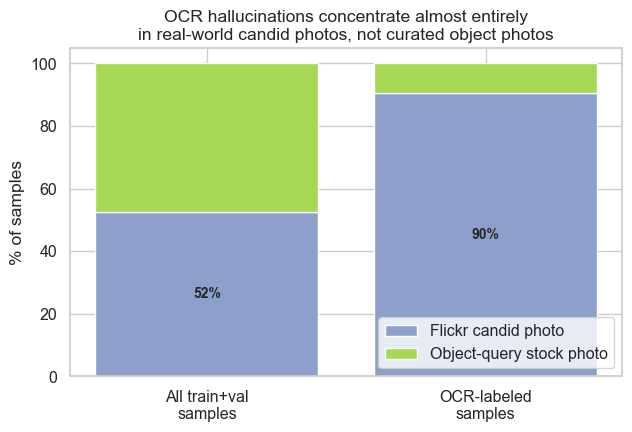

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
x = ["All train+val\nsamples", "OCR-labeled\nsamples"]
flickr_pct = [kind_df.loc["FLICKR (candid photo)", "all train+val samples %"],
              kind_df.loc["FLICKR (candid photo)", "OCR-labeled samples %"]]
object_pct = [100 - v for v in flickr_pct]
ax.bar(x, flickr_pct, label="Flickr candid photo", color=PALETTE[2])
ax.bar(x, object_pct, bottom=flickr_pct, label="Object-query stock photo", color=PALETTE[4])
for i, v in enumerate(flickr_pct):
    ax.text(i, v/2, f"{v:.0f}%", ha="center", va="center", fontsize=10, fontweight="bold")
ax.set_ylabel("% of samples")
ax.set_title("OCR hallucinations concentrate almost entirely\nin real-world candid photos, not curated object photos")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Finding:** Flickr-style photos are 53% of the data but **90% of OCR hallucinations**. Stock object photos almost never contain an OCR error — there's usually no incidental text to misread.

**Why it matters:** source new OCR data from real-world scene photos (signs, banners, storefronts, vehicles), not object catalogs.

---
## 5. Train vs. test: same volume, different themes

§3 showed test's OCR-context rate (12.1%) is close to train's (12.3%). Here we go one level deeper: by language, then by theme.

In [16]:
ocr_context_rate = []
for name, data in [("train", train), ("val", val), ("test", test)]:
    flagged = [d for d in data if is_ocr_context(d)]
    row = {"split": name, "overall_%": round(100 * len(flagged) / len(data), 1)}
    for lang in LANGUAGES:
        sub = [d for d in data if d["language"] == lang]
        sub_flagged = [d for d in sub if is_ocr_context(d)]
        row[f"{lang}_%"] = round(100 * len(sub_flagged) / len(sub), 1)
    ocr_context_rate.append(row)

ocr_rate_df = pd.DataFrame(ocr_context_rate).set_index("split")
ocr_rate_df

,overall_%,en_%,fr_%,it_%,zh_%
split,,,,,
train,12.3,13.2,10.6,13.2,12.3
val,12.9,13.7,12.5,15.2,10.4
test,12.1,13.2,8.4,14.1,12.5


**Finding:** Volume is stable across languages (~12% in both splits; French dips slightly). The real difference is in *theme*, not volume — next.

In [17]:
THEMES = collections.OrderedDict([
    ("sign / banner / board", r"\bsign\b|signboard|sign board|banner|board\b"),
    ("brand / logo", r"\bbrand\b|\blogo\b"),
    ("time / date / year", r"\btime\b|\bdate\b|\byear\b|\bclock\b"),
    ("event / concert / award", r"\bconcert\b|\bevent\b|award|festival"),
    ("place name (store/cafe/restaurant/stadium/river/mountain)", r"store name|cafe|restaurant|stadium|\briver\b|mountain|\blake\b|street name|street number"),
    ("vehicle / plate / number", r"\bcar\b|windshield|license|plate\b|digits"),
    ("document / book / paper", r"\bbook\b|\bpaper\b|title of|tombstone"),
    ("price", r"\bprice\b"),
    ("count of text elements", r"how many.*(word|letter|logo|digit)"),
])

def bucket(prompt):
    p = prompt.lower()
    hits = [name for name, pat in THEMES.items() if re.search(pat, p)]
    return hits if hits else ["other / unclassified"]

def theme_share(data_en):
    c = collections.Counter()
    for d in data_en:
        for b in bucket(d["prompt"]):
            c[b] += 1
    n = len(data_en)
    return {name: round(100 * c.get(name, 0) / n, 1) for name in list(THEMES.keys()) + ["other / unclassified"]}

train_en_ctx = [d for d in train + val if d["language"] == "en" and is_ocr_context(d)]
test_en_ctx = [d for d in test if d["language"] == "en" and is_ocr_context(d)]

theme_df = pd.DataFrame({
    f"train+val (n={len(train_en_ctx)})": theme_share(train_en_ctx),
    f"test (n={len(test_en_ctx)})": theme_share(test_en_ctx),
})
theme_df["shift (test - train)"] = (theme_df.iloc[:, 1] - theme_df.iloc[:, 0]).round(1)
theme_df.sort_values("shift (test - train)")

,train+val (n=506),test (n=159),shift (test - train)
time / date / year,11.1,0.6,-10.5
other / unclassified,37.0,30.2,-6.8
vehicle / plate / number,4.3,1.3,-3.0
count of text elements,3.4,1.3,-2.1
price,1.4,0.0,-1.4
event / concert / award,10.1,10.1,0.0
brand / logo,16.2,16.4,0.2
place name (store/cafe/restaurant/stadium/river/mountain),8.7,10.1,1.4
sign / banner / board,9.9,19.5,9.6
document / book / paper,0.4,10.7,10.3


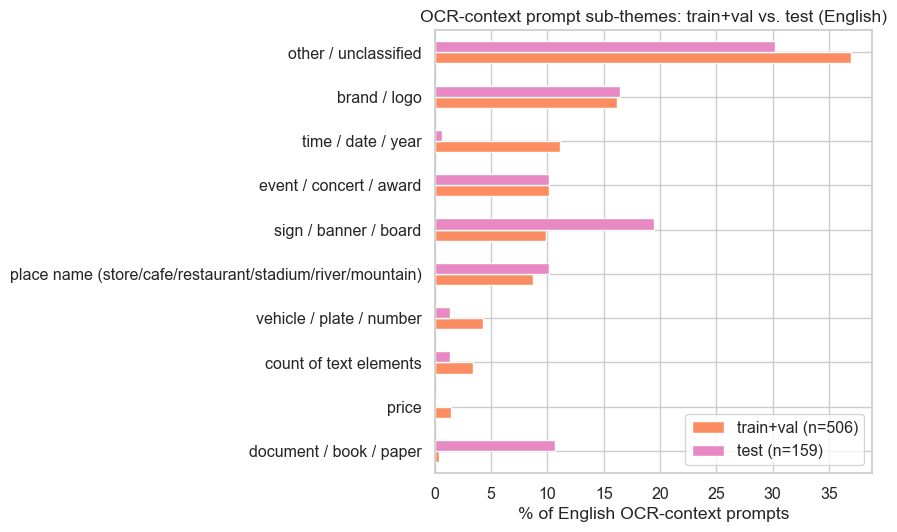

In [18]:
fig, ax = plt.subplots(figsize=(9, 5.5))
plot_df = theme_df.drop(columns=["shift (test - train)"]).sort_values(theme_df.columns[0])
plot_df.plot(kind="barh", ax=ax, color=[PALETTE[1], PALETTE[3]])
ax.set_xlabel("% of English OCR-context prompts")
ax.set_title("OCR-context prompt sub-themes: train+val vs. test (English)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Finding — the real shift is in theme, not volume:**

| Theme | Train | Test | Change |
|---|---|---|---|
| Document / book / paper | 0.4% | 10.7% | new in test |
| Sign / banner / board | 9.9% | 19.5% | ~2x higher |
| Time / date / year | 11.1% | 0.6% | mostly gone |
| Vehicle / plate / number | 4.3% | 1.3% | down |

**Train** over-indexes on timestamps and vehicle plates. **Test** leans into documents and signage — a gap external OCR data should target.

### 5.1 Eyeballing it

Train examples show the real hallucinated span (ground truth); test has no labels, so only the prompt is shown.

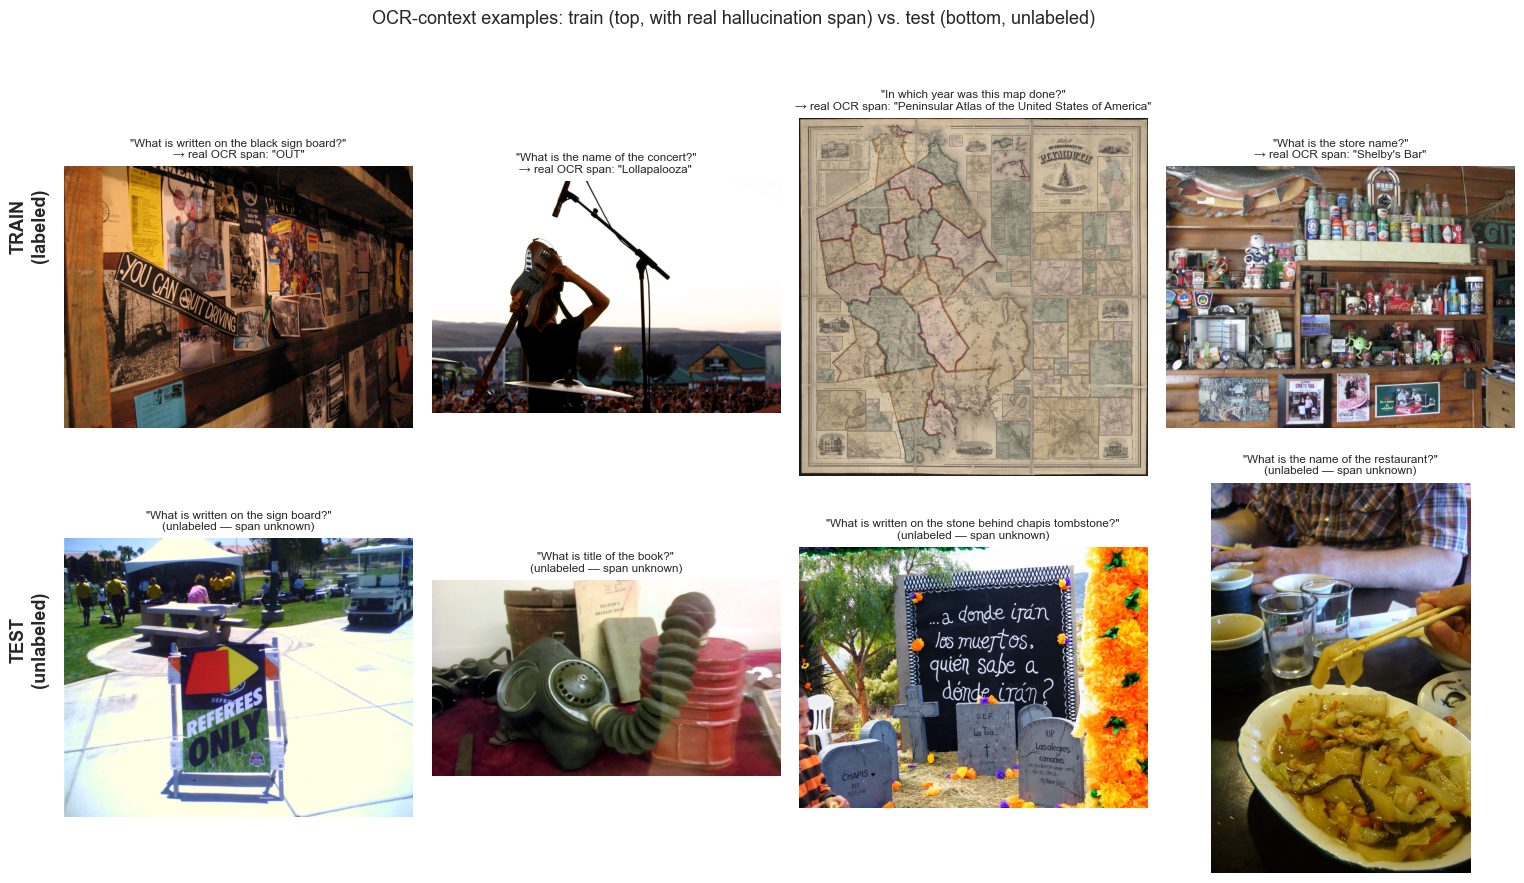

In [19]:
train_examples = ["train-en-1449", "train-en-9700", "train-en-9819", "train-en-727"]
test_examples = ["test-en-804", "test-en-500", "test-en-9618", "test-en-2529"]

by_id = {d["id"]: d for d in train + val + test}

fig, axes = plt.subplots(2, 4, figsize=(16, 9))
for col, sid in enumerate(train_examples):
    d = by_id[sid]
    span = first_ocr_span(d)
    span_text = d["response"][span["start"]:span["end"]] if span else "?"
    img = mpimg.imread(IMAGE_DIR / d["image_name"])
    axes[0, col].imshow(img)
    axes[0, col].axis("off")
    axes[0, col].set_title(f"\"{d['prompt']}\"\n→ real OCR span: \"{span_text}\"", fontsize=8.5)

for col, sid in enumerate(test_examples):
    d = by_id[sid]
    img = mpimg.imread(IMAGE_DIR / d["image_name"])
    axes[1, col].imshow(img)
    axes[1, col].axis("off")
    axes[1, col].set_title(f"\"{d['prompt']}\"\n(unlabeled — span unknown)", fontsize=8.5)

fig.text(0.06, 0.74, "TRAIN\n(labeled)", fontsize=13, fontweight="bold", rotation=90, va="center", ha="center")
fig.text(0.06, 0.28, "TEST\n(unlabeled)", fontsize=13, fontweight="bold", rotation=90, va="center", ha="center")
plt.suptitle("OCR-context examples: train (top, with real hallucination span) vs. test (bottom, unlabeled)", fontsize=13)
plt.tight_layout(rect=[0.07, 0, 1, 0.95])
plt.show()

Visually: train skews to outdoor event/street photography; test skews to close-up documents (book covers, engraved stone, signage). Same prompt style, different photographic setting.

The 4 train spans also show 4 different error types: a truncated read (`'OUT'`), a wrong-but-plausible name (`'Lollapalooza'`), a fully fabricated title (`'Peninsular Atlas...'`), and a wrong store name (`"Shelby's Bar"`) — OCR errors vary in *kind*, not just length.

---
## 6. Summary and implications for synthetic OCR data

| Question | Finding |
|---|---|
| Class balance | OCR is the rarest hallucination category: ~1,284 train spans / 730 samples, vs. 13,600–14,500 for mischaracterization and invention (~11x fewer). |
| Span shape | Short (median 5 chars) — a word, code, or a few digits, not a sentence. |
| Clean OCR-context samples in train? | Yes — only ~29% of "sounds like OCR" prompts carry an OCR label; **~22% are fully clean**. Negatives matter as much as positives. |
| Does OCR matter in `test`? | Yes, proportionally as much as `train` (12.1% vs. 12.3% OCR-context rate), despite being unlabeled. |
| Need a "text-reading" prompt? | No — **~41%** of real OCR hallucinations occur on prompts that never mention text; the model volunteers a misread while elaborating on something else. |
| Visual domain | Occurs almost exclusively (~90%) in real candid photos, almost never in curated stock photos. |
| Train/test image overlap | Zero — test is 400 entirely unseen images. |
| Train vs. test theme | Shifted: test has far more document/book/signage prompts; train over-indexes on timestamp/date and vehicle-plate prompts. |

### What this implies for building synthetic OCR data

1. **Source real-world photos with incidental visible text** — signs, storefronts, banners, vehicles, event photography — not object-catalog images.
2. **Don't gate seed selection on prompt keywords alone.** ~41% of real hallucinations have no text-cue prompt. The real requirement is "image has legible text," independent of the question.
3. **Target the test-skewed themes** (documents/books, signage) using external OCR-in-the-wild datasets — COCO-Text / TextVQA / HierText (signage), SROIE (receipts/menus), FUNSD / book-cover sets (documents) — rather than synthesizing text from scratch.
4. **Keep spans short and word-bounded** (~5 chars median) — no fixed-width windows or sentence-level spans.
5. **Preserve some clean text-reading examples** so the detector learns to judge correctness, not pattern-match on "prompt mentions a sign/date/brand."
6. **Match error type to theme** using the existing 6-type OCR taxonomy (`docs/OCR_Taxonomy.md`) — e.g. digit misreads for dates/prices, partial reads for long signage/menus.